[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/14_clustering.ipynb)

# 14 · Clustering: Finding Groups Nobody Labeled

**Part 2 — Classical unsupervised learning** · Notebook 14 of 27

Every notebook so far had an answer key: house prices, tumor labels, spam or not. Now the labels are gone. We get a pile of data points and one question: **are there groups in here?** Customers who shop alike, tissue regions with the same stain, documents about the same topic, pixels of the same color. That's **clustering**, and it is the first and most widely used tool of *unsupervised learning*.

Clustering looks easy (just "put similar things together"), but it hides three hard choices that this notebook makes visible: **how to represent** each object as numbers, **how to measure** similarity, and **what shape** a group is allowed to have. Change any of them and the "groups" change too.

**What you'll learn**

1. What clustering is, and how it differs from classification
2. Representation first: scaling, and why documents need cosine similarity
3. Distance functions: Minkowski balls, Hamming, edit distance
4. **K-means**: the objective and the assign–update algorithm, built and animated
5. Why k-means always converges, and why it can converge to a bad answer
6. **k-means++**: a smarter start
7. Choosing $k$: the elbow and the silhouette
8. **Image compression** by clustering colors
9. **Generalized k-means**: k-medians, k-medoids, and clustering strings
10. Where k-means fails
11. **Hierarchical clustering**: linkages and dendrograms
12. Beyond k-means: DBSCAN and spectral clustering
13. Evaluating a clustering without (and with) labels

*Course map: ISYE 4600 W2 (Clustering: representation, distances, k-means, generalized k-means, hierarchical clustering) and HW1 Q4–Q6 (k-means concepts, color-quantization image compression, MNIST with ℓ2 vs. ℓ1); CX 4240 lecture 16 (k-means as coordinate descent, elbow, initialization, generalized k-means, hierarchical clustering) and HW3 Q2 (k-means from scratch with the elbow method).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from sklearn.datasets import make_blobs, make_moons, make_circles, load_digits, load_sample_image
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import time
print("Ready ✓")

Setup complete ✓


Ready ✓


---
## 1. Clustering: finding groups without labels

Clustering asks us to **partition** data into groups so that points inside a group are more similar to each other than to points in other groups (ISYE W2). There is no ground truth to check against, so nothing tells the algorithm whether it's "right".

A good first experiment: take 1,797 images of handwritten digits (8×8 pixels each, so a vector in $\mathbb{R}^{64}$), **hide the labels**, and ask for 10 groups. Below, each image is a cluster's average (its "center"), and the bar underneath shows which true digits ended up in that cluster.

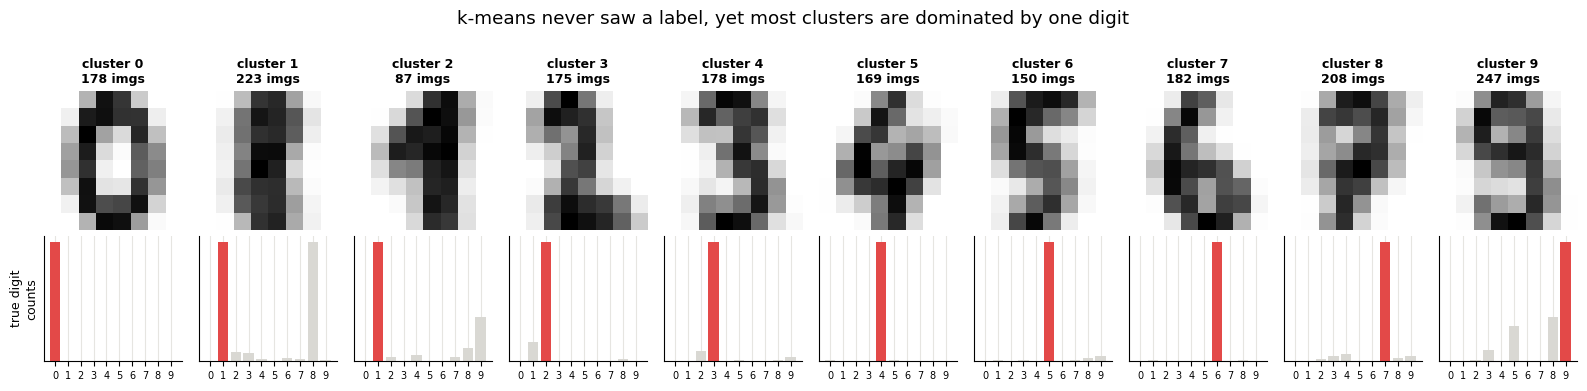

In [2]:
digits = load_digits(); Xd, yd = digits.data / 16.0, digits.target
km = KMeans(10, n_init=10, random_state=0).fit(Xd)

fig, axes = plt.subplots(2, 10, figsize=(16, 3.8), gridspec_kw=dict(height_ratios=[1.3, 1]))
order = np.argsort([np.bincount(yd[km.labels_ == j], minlength=10).argmax() for j in range(10)])
for col, j in enumerate(order):
    axes[0, col].imshow(km.cluster_centers_[j].reshape(8, 8), cmap="gray_r"); axes[0, col].axis("off")
    counts = np.bincount(yd[km.labels_ == j], minlength=10)
    axes[0, col].set_title(f"cluster {col}\n{counts.sum()} imgs", fontsize=9)
    axes[1, col].bar(range(10), counts, color=[C["red"] if d == counts.argmax() else C["light"] for d in range(10)])
    axes[1, col].set_xticks(range(10)); axes[1, col].tick_params(labelsize=7); axes[1, col].set_yticks([])
axes[1, 0].set_ylabel("true digit\ncounts", fontsize=9)
fig.suptitle("k-means never saw a label, yet most clusters are dominated by one digit", y=1.02); fig.tight_layout(); plt.show()

Most clusters line up with one digit (the red bar), so the structure the labels describe is mostly **already there in the pixels**. Some don't: look for clusters that mix 1s with 8s, or 9s with 3s and 5s, and for digits split across two clusters. Clusters approximate the hidden ("latent") classes without ever being told about them, and where they disagree with the labels, they often reveal sub-styles (two ways of writing a 1, say).

> 🤔 **Question: How is clustering different from classification?**
>
> Classification learns a map $x \mapsto y$ from labeled examples and can be scored against held-out labels. Clustering only sees $x$. It has to invent the groups *and* decide what "similar" means, and there's no single correct answer: the digits could just as well be grouped by stroke thickness or slant. That's why the choices of representation and distance matter so much more here than in supervised learning.

---
## 2. Representation first: what are we actually comparing?

Clustering algorithms compare **vectors**, so every object has to become one first. That conversion often matters more than the algorithm itself (ISYE W2: *"features are not given, but designed"*).

### Scaling: who gets to dominate the distance?

ISYE's example describes cars by horsepower, weight, MPG, and price. Price is measured in dollars (tens of thousands), MPG in single or double digits. In Euclidean distance, a \$5,000 price gap swamps a 20-MPG gap, so the "clusters" are really just price brackets.

Below are 200 made-up cars of two kinds: sporty ones (high horsepower, low MPG) and economy ones (the reverse), with prices that vary a lot *within* each kind.

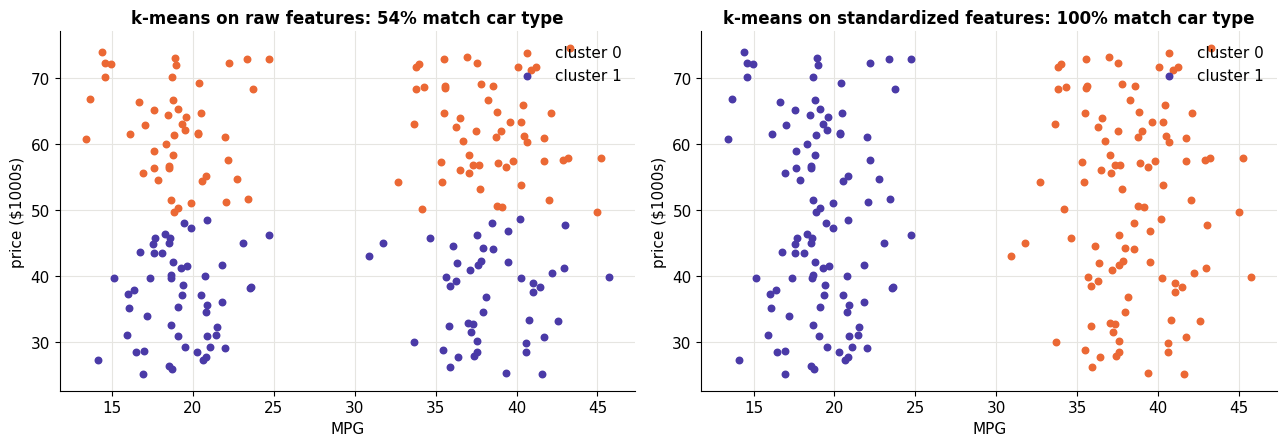

Feature spreads (std): {'horsepower': 132.0, 'weight (lb)': 493.4, 'MPG': 10.0, 'price ($)': 14252.0}


In [3]:
r_ = np.random.default_rng(3)
n = 100
sport = np.column_stack([r_.normal(430, 40, n), r_.normal(3900, 200, n), r_.normal(19, 2.5, n), r_.uniform(25e3, 75e3, n)])
econ  = np.column_stack([r_.normal(170, 30, n), r_.normal(3000, 200, n), r_.normal(38, 3.0, n), r_.uniform(25e3, 75e3, n)])
cars = np.vstack([sport, econ]); kind = np.r_[np.zeros(n, int), np.ones(n, int)]
feat = ["horsepower", "weight (lb)", "MPG", "price ($)"]

lab_raw = KMeans(2, n_init=10, random_state=0).fit_predict(cars)
cars_z = (cars - cars.mean(0)) / cars.std(0)                   # standardize: mean 0, std 1 per feature
lab_z = KMeans(2, n_init=10, random_state=0).fit_predict(cars_z)

def agreement(lab, truth):                                     # cluster ids are arbitrary: take the better matching
    return max(np.mean(lab == truth), np.mean(lab != truth))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, lab, name in zip(axes, [lab_raw, lab_z], ["raw features", "standardized features"]):
    for g, col in zip([0, 1], [C["orange"], C["violet"]]):
        m = lab == g
        ax.scatter(cars[m, 2], cars[m, 3] / 1e3, s=22, color=col, marker="o", label=f"cluster {g}")
    ax.set(xlabel="MPG", ylabel="price ($1000s)", title=f"k-means on {name}: {agreement(lab, kind):.0%} match car type")
    ax.legend(loc="upper right")
fig.tight_layout(); plt.show()
print("Feature spreads (std):", {f: round(float(v), 1) for f, v in zip(feat, cars.std(0))})

On raw features, k-means splits the cars into **cheap and expensive** (a horizontal cut), because price's standard deviation is about 14,000 while MPG's is about 10. After standardizing every feature to unit variance, the split follows **car type**, which is the structure actually in the data.

Standardizing isn't automatically right either: it gives every feature equal say, including noisy, irrelevant ones. ISYE's warning applies: *more features don't always help; noisy or redundant ones yield poor clusters.* Scaling is a modeling decision about what "similar" should mean.

### Documents: Euclidean distance groups by length, not topic

Text has no natural numeric form. The standard trick is the **bag of words**: fix a vocabulary and represent each document by how often each word appears (ISYE W2). The resulting term–document matrix is big and mostly zeros:

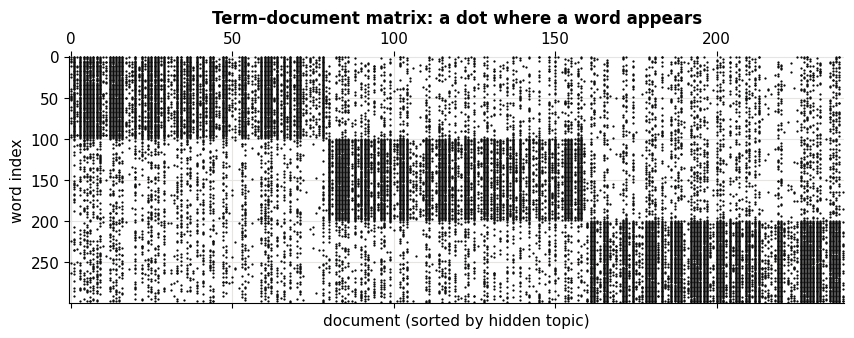

240 documents × 300 words; 29% of entries are nonzero


In [4]:
r_ = np.random.default_rng(7)
V, topics = 300, 3
topic_words = np.full((topics, V), 0.2)                        # each topic favors its own block of 100 words
for t in range(topics):
    topic_words[t, t * 100:(t + 1) * 100] = 3.0
topic_words /= topic_words.sum(1, keepdims=True)
n_docs = 240
doc_topic = np.repeat(np.arange(topics), n_docs // topics)
doc_len = r_.choice([30, 400], size=n_docs)                    # short notes and long reports, mixed
counts = np.array([r_.multinomial(L, topic_words[t]) for L, t in zip(doc_len, doc_topic)]).astype(float)

perm = r_.permutation(n_docs); counts, doc_topic, doc_len = counts[perm], doc_topic[perm], doc_len[perm]
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.spy(counts[np.argsort(doc_topic)].T > 0, aspect="auto", markersize=0.6, color=C["ink"])
ax.set(xlabel="document (sorted by hidden topic)", ylabel="word index", title="Term–document matrix: a dot where a word appears")
plt.show()
print(f"{counts.shape[0]} documents × {counts.shape[1]} words; {np.mean(counts > 0):.0%} of entries are nonzero")

The three topic blocks are visible because we sorted by the hidden topic. Long documents are dense columns; short ones are sparse. Now cluster them two ways: raw counts with Euclidean distance, and **length-normalized** counts (each row divided by its norm), which makes Euclidean distance equivalent to **cosine similarity** $\cos(x, y) = \frac{x^\top y}{\|x\|\|y\|}$:

In [5]:
def purity(labels, truth):
    """Fraction of points whose cluster's majority class matches their own class (HW1 Q6's purity score)."""
    return sum(np.bincount(truth[labels == j]).max() for j in np.unique(labels)) / len(truth)

lab_euc = KMeans(3, n_init=10, random_state=0).fit_predict(counts)
unit = counts / np.linalg.norm(counts, axis=1, keepdims=True)
lab_cos = KMeans(3, n_init=10, random_state=0).fit_predict(unit)

for name, lab in [("raw counts, Euclidean", lab_euc), ("normalized rows (= cosine)", lab_cos)]:
    tab = pd.crosstab(pd.Series(lab, name="cluster"), [pd.Series(doc_topic, name="topic"), pd.Series(doc_len, name="length")])
    print(f"\n{name}:  purity {purity(lab, doc_topic):.2f}")
    print(tab.to_string())


raw counts, Euclidean:  purity 0.70
topic     0       1       2    
length  30  400 30  400 30  400
cluster                        
0        38  42  37   0  35   0
1         0   0   0  43   0   0
2         0   0   0   0   0  45

normalized rows (= cosine):  purity 1.00
topic     0       1       2    
length  30  400 30  400 30  400
cluster                        
0        38  42   0   0   0   0
1         0   0  37  43   0   0
2         0   0   0   0  35  45


With raw counts, one cluster collects the **short documents** from every topic: two 30-word notes are close in Euclidean distance simply because both vectors are near zero, whatever they're about. After normalizing, only the *direction* of each vector matters (which words, in what proportions), and the clusters follow topic. This is why text clustering and search use cosine similarity, and why "spherical k-means" (k-means on normalized vectors) exists.

> 🤔 **Question: What could go wrong if we cluster images without resizing them?** (ISYE W2)
>
> First, the vectors don't even have the same length: a 320×240×3 image is a vector in $\mathbb{R}^{230400}$, a 640×480 one in $\mathbb{R}^{921600}$, so distance isn't defined. Padding or cropping makes it defined but meaningless: the same cat photographed closer lands far away in pixel space. Resizing to a common shape fixes the first problem; the second is why modern pipelines cluster **learned features** (from a CNN, notebook 21, or a contrastive model, notebook 24) instead of raw pixels.

---
## 3. Distance functions

A distance (or dissimilarity) $d(x, y)$ should satisfy three properties (ISYE W2, CX lecture 16):

- **Symmetry:** $d(x, y) = d(y, x)$. Otherwise "Alex looks like Bob, but Bob looks nothing like Alex."
- **Positive separability:** $d(x, y) \ge 0$, with $d(x, y) = 0$ only if $x = y$.
- **Triangle inequality:** $d(x, y) \le d(x, z) + d(z, y)$. A detour can't be shorter.

### The Minkowski family

$$d_p(x, y) = \Big(\sum_{j=1}^{d}|x_j - y_j|^p\Big)^{1/p}, \qquad p \ge 1$$

$p = 2$ is Euclidean, $p = 1$ is **Manhattan** (city blocks), and $p \to \infty$ is **Chebyshev**, $\max_j |x_j - y_j|$. The clearest way to see the difference is the **unit ball**: all points at distance 1 from the origin. 🎚️ **Change $p$** (values below 1 are allowed so you can see what breaks):

In [6]:
def plot_ball(p=2.0):
    t = np.linspace(0, 2 * np.pi, 800)
    u, v = np.cos(t), np.sin(t)
    s = (np.abs(u) ** p + np.abs(v) ** p) ** (1 / p)            # scale each direction to norm 1
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    ax = axes[0]
    for q, col in [(1, C["light"]), (2, C["light"]), (50, C["light"])]:
        sq = (np.abs(u) ** q + np.abs(v) ** q) ** (1 / q); ax.plot(u / sq, v / sq, color=col, lw=1.2)
    ax.fill(u / s, v / s, color=C["blue"], alpha=0.25); ax.plot(u / s, v / s, color=C["blue"], lw=2.5)
    ax.set(aspect="equal", xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), title=f"unit ball of the p = {p:.2f} distance\n(grey: p = 1, 2, ∞)")
    # triangle inequality check: x=(0,0), z=(1,0), y=(1,1)
    dp = lambda a, b: (np.abs(np.subtract(a, b)) ** p).sum() ** (1 / p)
    x, z, y = (0, 0), (1, 0), (1, 1)
    ax = axes[1]
    ax.plot(*zip(x, z, y), "o-", color=C["orange"], lw=2); ax.plot(*zip(x, y), "o--", color=C["violet"], lw=2)
    for pt, nm in zip([x, z, y], "xzy"):
        ax.annotate(nm, pt, xytext=(6, 6), textcoords="offset points", fontsize=13)
    direct, detour = dp(x, y), dp(x, z) + dp(z, y)
    ok = direct <= detour + 1e-12
    ax.set(aspect="equal", xlim=(-0.3, 1.4), ylim=(-0.3, 1.4),
           title=f"direct d(x,y) = {direct:.2f}   detour = {detour:.2f}\ntriangle inequality {'holds ✓' if ok else 'FAILS ✗'}")
    ax.grid(True); plt.tight_layout(); plt.show()

interact(plot_ball, p=FloatSlider(value=2.0, min=0.5, max=8.0, step=0.25, description="p"));

At $p = 1$ the ball is a diamond, at $p = 2$ a circle, and as $p$ grows it fills out toward a square. For $p < 1$ the ball turns **star-shaped** (non-convex), and the triangle inequality fails: going $x \to z \to y$ along the axes becomes *shorter* than going straight. That's why the Minkowski distance requires $p \ge 1$.

### Hamming distance: counting mismatches

When every feature is binary, Manhattan distance just **counts the positions that differ**. That count is the Hamming distance. ISYE's 17-bit example:

In [7]:
x = np.array([0,1,1,0,0,1,0,0,1,0,0,1,1,1,0,0,1]); y = np.array([0,1,1,1,0,0,0,0,1,1,1,1,1,1,0,1,1])
diff = x != y
print("x:   ", "".join(map(str, x))); print("y:   ", "".join(map(str, y))); print("diff:", "".join("^" if d else " " for d in diff))
print(f"Hamming distance = {diff.sum()}   (Manhattan = {np.abs(x - y).sum()}, squared Euclidean = {((x - y)**2).sum()})")

x:    01100100100111001
y:    01110000111111011
diff:    ^ ^   ^^    ^ 
Hamming distance = 5   (Manhattan = 5, squared Euclidean = 5)


> 🤔 **Question: Why would Euclidean distance be misleading for one-hot encoded data?** (ISYE W2)
>
> On *pure* 0/1 vectors it isn't wrong in ranking: as the printout shows, squared Euclidean distance equals Hamming distance, so the nearest neighbors are the same. The trouble starts in two places. (1) **Mixed data**: a category mismatch always contributes exactly 2 to the squared distance (one 1→0 and one 0→1), while a numeric column like price can contribute millions, so categories become invisible unless you scale. (2) **Label encoding instead of one-hot**: coding cities as Chicago = 1, Austin = 2, Boston = 3 makes Chicago "closer" to Austin than to Boston for no reason. For mixed data a common fix is a **Gower-style** distance: Hamming on the categorical part, range-scaled absolute differences on the numeric part, averaged.

### Edit distance: how much work to turn one string into another

Strings (words, DNA, sequences) have no fixed length, so none of the above apply. The **edit distance** counts the cheapest sequence of insertions, deletions, and substitutions that transforms one string into the other (ISYE W2). It's a minimum over all alignments, which **dynamic programming** finds: let $D[i, j]$ be the cheapest way to turn the first $i$ letters of $x$ into the first $j$ letters of $y$. Then

$$D[i, j] = \min\big(D[i{-}1, j] + c_{\text{del}},\;\; D[i, j{-}1] + c_{\text{ins}},\;\; D[i{-}1, j{-}1] + c_{\text{sub}}\cdot[x_i \ne y_j]\big)$$

The alignment drawn on the slide costs 10.  The cheapest alignment (DP) costs 5.
Unit costs (classic Levenshtein): 5.0


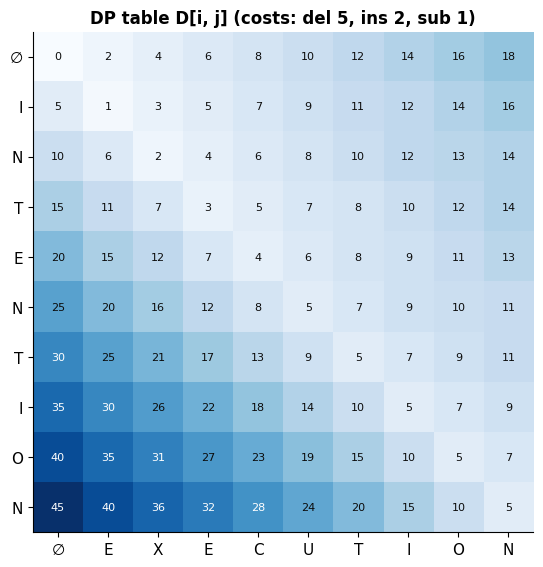

In [8]:
def edit_distance(a, b, c_del=1, c_ins=1, c_sub=1, table=False):
    D = np.zeros((len(a) + 1, len(b) + 1))
    D[:, 0] = np.arange(len(a) + 1) * c_del                    # delete everything
    D[0, :] = np.arange(len(b) + 1) * c_ins                    # insert everything
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            D[i, j] = min(D[i - 1, j] + c_del, D[i, j - 1] + c_ins, D[i - 1, j - 1] + c_sub * (a[i - 1] != b[j - 1]))
    return (D[-1, -1], D) if table else D[-1, -1]

# ISYE's slide: deletion costs 5, insertion 2, substitution 1
lecture_alignment = 1 * 5 + 3 * 1 + 1 * 2
best, D = edit_distance("INTENTION", "EXECUTION", c_del=5, c_ins=2, c_sub=1, table=True)
print(f"The alignment drawn on the slide costs {lecture_alignment}.  The cheapest alignment (DP) costs {best:.0f}.")
print("Unit costs (classic Levenshtein):", edit_distance("INTENTION", "EXECUTION"))

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(D, cmap="Blues"); ax.grid(False)
for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        ax.text(j, i, f"{D[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if D[i, j] > D.max() * 0.6 else C["ink"])
ax.set_xticks(range(10)); ax.set_xticklabels(["∅"] + list("EXECUTION")); ax.set_yticks(range(10)); ax.set_yticklabels(["∅"] + list("INTENTION"))
ax.set_title("DP table D[i, j] (costs: del 5, ins 2, sub 1)"); plt.show()

Interesting: the alignment on the slide (one deletion, three substitutions, one insertion) costs 10, but with these costs a cheaper one exists. Both words have nine letters, and lining them up position by position needs only five substitutions (I→E, N→X, T→E, E→C, N→U), costing 5. Making deletions expensive (5) makes the DP avoid them entirely. That's the point of defining edit distance as a **minimum**: the cost structure, not a hand-drawn alignment, decides the answer. With unit costs the distance is also 5.

---
## 4. K-means: objective and algorithm

Given $m$ points $x^1, \dots, x^m \in \mathbb{R}^d$, k-means looks for $k$ centers $c^1, \dots, c^k$ and an assignment $\pi(i) \in \{1, \dots, k\}$ of each point to a center, minimizing the average squared distance from each point to its center (ISYE W2):

$$J(\pi, c) = \frac{1}{m}\sum_{i=1}^{m}\big\|x^i - c^{\pi(i)}\big\|^2$$

That's the **within-cluster variance**. Minimizing over both at once is hard (more on that in section 5), but minimizing over **one with the other fixed** is easy:

- **Fix the centers, choose assignments.** Each point's term only involves its own $\pi(i)$, so pick the nearest center: $\pi(i) = \arg\min_j \|x^i - c^j\|^2$.
- **Fix the assignments, choose centers.** Each cluster's terms only involve its own center. Setting the gradient of $\sum_{i:\pi(i)=j}\|x^i - c\|^2$ to zero gives $-2\sum (x^i - c) = 0$, so $c^j = $ **the mean** of the cluster's points.

Alternating these two steps is **Lloyd's algorithm** (1957), the algorithm everyone means by "k-means". CX 4240 calls it **block coordinate descent**: optimize one block of variables, then the other.

In [9]:
def sq_dists(X, centers):
    """All squared distances ||x_i - c_j||^2 at once, via ||x||^2 - 2 x·c + ||c||^2 (fast, no 3-D arrays)."""
    return np.maximum((X ** 2).sum(1)[:, None] - 2 * X @ centers.T + (centers ** 2).sum(1)[None, :], 0)

def kmeans(X, k, init=None, seed=0, max_iter=300, history=False):
    """Lloyd's algorithm from scratch. Returns labels, centers, objective J, iterations (and optional history)."""
    r = np.random.default_rng(seed)
    centers = X[r.choice(len(X), k, replace=False)].copy() if init is None else np.array(init, float).copy()
    hist, labels = [], None
    for it in range(1, max_iter + 1):
        D = sq_dists(X, centers)
        new = D.argmin(1)                                      # 1) assignment step
        if history: hist.append(("assign", centers.copy(), new.copy(), D[np.arange(len(X)), new].mean()))
        if labels is not None and np.array_equal(new, labels):
            break                                              # assignments stopped changing: converged
        labels = new
        for j in range(k):                                     # 2) update step
            members = X[labels == j]
            if len(members) == 0:                              # empty cluster: re-seed it at the worst-served point
                centers[j] = X[D[np.arange(len(X)), labels].argmax()]
            else:
                centers[j] = members.mean(0)
        if history: hist.append(("update", centers.copy(), labels.copy(), sq_dists(X, centers)[np.arange(len(X)), labels].mean()))
    J = sq_dists(X, centers)[np.arange(len(X)), labels].mean()
    return (labels, centers, J, it, hist) if history else (labels, centers, J, it)

Xb, yb = make_blobs(400, centers=[(-3, -2), (3, -2.5), (0, 3), (4, 3.5)], cluster_std=[1.0, 1.1, 0.9, 0.8], random_state=0)
labels, centers, J, iters = kmeans(Xb, 4, seed=0)
start = Xb[np.random.default_rng(0).choice(len(Xb), 4, replace=False)]   # the same random start kmeans() used
ref = KMeans(4, init=start, n_init=1, algorithm="lloyd").fit(Xb)
print(f"from scratch: J = {J:.4f} after {iters} iterations")
print(f"scikit-learn (same starting centers): J = {ref.inertia_ / len(Xb):.4f}")

from scratch: J = 1.7806 after 8 iterations
scikit-learn (same starting centers): J = 1.7806


Same objective as scikit-learn from the same starting centers. Now let's **watch** it. Each frame is one half-step. The background shows the **Voronoi cells**: the region of the plane closest to each center. The assignment step colors points by cell; the update step moves each center (✕) to the mean of its points, which redraws the cells.

In [10]:
labels, centers, J, iters, hist = kmeans(Xb, 4, init=np.array([[-1, 4.5], [-0.5, 4.0], [0, 3.5], [5, -4]]), history=True)
cols = [C["blue"], C["orange"], C["aqua"], C["violet"]]
from matplotlib.colors import ListedColormap
gx, gy = np.meshgrid(np.linspace(-7, 8, 300), np.linspace(-6.5, 7, 300)); G = np.column_stack([gx.ravel(), gy.ravel()])

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw=dict(width_ratios=[1.25, 1]))
def frame(t):
    ax.clear(); ax2.clear()
    kind_, cen, lab, Jt = hist[t]
    prev_cen = hist[t - 1][1] if t > 0 else cen
    cell = sq_dists(G, cen).argmin(1).reshape(gx.shape)
    ax.contourf(gx, gy, cell, levels=np.arange(-0.5, 4.5), colors=cols, alpha=0.13)
    ax.scatter(*Xb.T, s=12, c=[cols[l] for l in lab], alpha=0.85)
    if kind_ == "update":
        for a, b in zip(prev_cen, cen):
            ax.annotate("", b, a, arrowprops=dict(arrowstyle="->", color=C["ink"], lw=1.5))
    ax.scatter(*cen.T, marker="X", s=260, c=cols, edgecolor="white", linewidth=2, zorder=5)
    ax.set(xlim=(-7, 8), ylim=(-6.5, 7), aspect="equal", title=f"step {t + 1}: {kind_} step")
    ax.grid(False)
    Js = [h[3] for h in hist[:t + 1]]
    ax2.plot(range(1, t + 2), Js, "o-", color=C["red"])
    for i_, h in enumerate(hist[:t + 1]):
        ax2.scatter(i_ + 1, h[3], s=60, color=C["blue"] if h[0] == "assign" else C["orange"], zorder=3)
    ax2.set(xlim=(0.5, len(hist) + 0.5), ylim=(0, hist[0][3] * 1.05), xlabel="half-step", ylabel="objective J",
            title="J never goes up\n(blue = after assign, orange = after update)")
anim = animation.FuncAnimation(fig, frame, frames=len(hist), interval=700)
show_anim(anim)

We started three centers crowded together at the top and one far away at the bottom right. Within a few rounds they spread out, the cells settle on the four blobs, and the objective (right) drops at **every** half-step, both blue (assignment) and orange (update) dots.

> 🤔 **Question: What happens to the assignments if two centers are very close?** (ISYE W2)
>
> The boundary between two centers' cells is the **perpendicular bisector** of the segment joining them. If they sit close together inside one blob, the bisector slices that blob in two, and each center gets half of it. You can see this in the first frames: the three crowded centers split the top blob three ways. The update step then pulls each center toward the middle of its slice, which pushes them apart, until (with luck) each finds its own blob.

---
## 5. Why k-means always converges, and why it can converge to a bad answer

**Convergence.** Two facts (ISYE W2, HW1 Q4):

1. **$J$ never increases.** The assignment step picks, for each point, the best center given the current centers, so it can't make $J$ worse. The update step picks the best centers given the current assignments (the mean minimizes squared distance), so it can't make $J$ worse either.
2. **There are finitely many assignments**: at most $k^m$ ways to label $m$ points. Each assignment determines its centers, and hence its $J$.

If the assignments change, $J$ strictly decreases (with a consistent tie-breaking rule), so no assignment can ever be revisited. A sequence that never repeats, drawn from a finite set, must stop. So Lloyd's algorithm **terminates in a finite number of steps**, and in practice usually within a few dozen.

> 🤔 **Question: Could this loop run forever?** (ISYE W2)
>
> Only through **ties**. If a point is exactly equidistant from two centers and the code breaks the tie differently on different iterations, labels can flip back and forth without $J$ changing. A fixed tie-break rule (like `argmin`'s "lowest index wins") removes that. Separately, "finite" can be enormous in theory: there are constructed examples where Lloyd's algorithm needs exponentially many iterations. Real data almost never does that, and implementations also cap the number of iterations.

**But convergence is to a local minimum.** Finding the global minimum of $J$ is **NP-hard** (ISYE W2): it's a search over discrete assignments, and for our 400 points with $k = 4$ there are $4^{400} \approx 10^{241}$ of them. Lloyd's algorithm only finds an assignment that neither half-step can improve. Which one depends on where it **starts**.

Let's run k-means 300 times from random starting centers on data with 8 blobs and look at where it ends up:

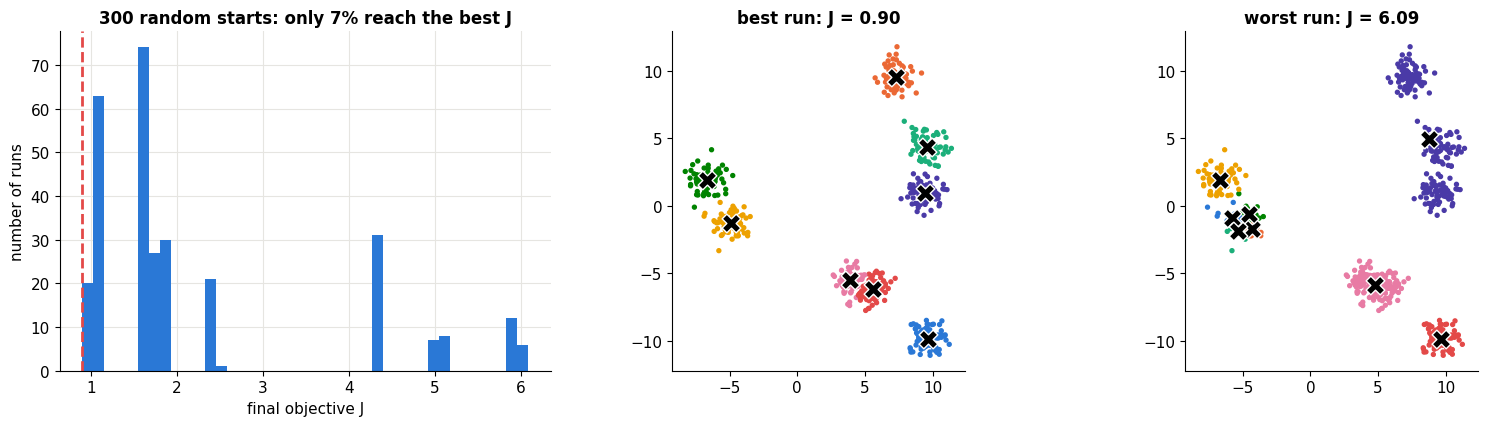

In [11]:
X8, y8 = make_blobs(600, centers=8, cluster_std=0.7, random_state=4)
runs = [kmeans(X8, 8, seed=s) for s in range(300)]
Js = np.array([r[2] for r in runs])
best_J = Js.min()

fig = plt.figure(figsize=(16, 4.4))
ax = fig.add_subplot(1, 3, 1)
ax.hist(Js, bins=40, color=C["blue"]); ax.axvline(best_J, color=C["red"], ls="--")
ax.set(xlabel="final objective J", ylabel="number of runs", title=f"300 random starts: only {np.mean(Js < best_J * 1.001):.0%} reach the best J")
pal8 = [C[c] for c in ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]
for pos, idx, name in [(2, Js.argmin(), "best run"), (3, Js.argmax(), "worst run")]:
    lab, cen, J_, _ = runs[idx]
    ax = fig.add_subplot(1, 3, pos)
    ax.scatter(*X8.T, s=8, c=[pal8[l] for l in lab]); ax.scatter(*cen.T, marker="X", s=180, c="k", edgecolor="white")
    ax.set(title=f"{name}: J = {J_:.2f}", aspect="equal"); ax.grid(False)
fig.tight_layout(); plt.show()

Most runs end in a **local minimum**: typically one center sits between two blobs (merging them into one cluster) while two centers share a single blob. Neither half-step can fix this: moving one center across the plane would require going *uphill* in $J$ first.

> 🤔 **Question: If initialization matters so much, is k-means unreliable?** (ISYE W2)
>
> Not if you use it properly. The standard remedies are cheap: **(1) restart** many times from different random centers and keep the run with the lowest $J$ (scikit-learn's `n_init`), and **(2) start smarter**, with k-means++ (next section). Every single run is guaranteed to converge; you just can't trust any *one* run to be the global optimum. NP-hardness rules out a guaranteed global solution, not good local ones.

---
## 6. k-means++: a smarter start

The worst starts put several centers in the same blob. **k-means++** (Arthur & Vassilvitskii, 2007) spreads them out on purpose:

1. Pick the first center uniformly at random from the data.
2. For each point, compute $D(x)$, the distance to the **nearest center chosen so far**.
3. Pick the next center at random with probability **proportional to $D(x)^2$**. Far-away points are likely; points next to an existing center are almost never picked.
4. Repeat until there are $k$ centers, then run Lloyd's algorithm as usual.

It's randomized, so it still has bad luck sometimes, but it comes with a guarantee: the expected $J$ right after seeding is within a factor $O(\log k)$ of the optimum.

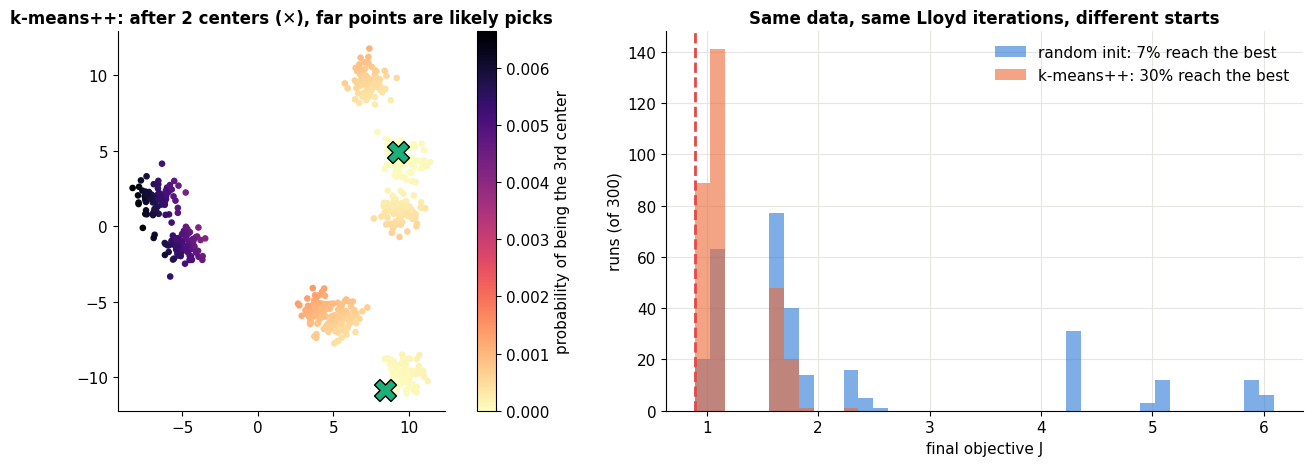

median final J:  random 1.670   k-means++ 1.055   (best found 0.897)


In [12]:
def kmeans_pp_init(X, k, seed=0):
    r = np.random.default_rng(seed)
    centers = [X[r.integers(len(X))]]
    for _ in range(k - 1):
        D2 = sq_dists(X, np.array(centers)).min(1)             # squared distance to the nearest chosen center
        centers.append(X[r.choice(len(X), p=D2 / D2.sum())])
    return np.array(centers)

# Illustrate step 3 after two centers have been chosen
r_ = np.random.default_rng(5); first = kmeans_pp_init(X8, 2, seed=5)
D2 = sq_dists(X8, first).min(1); prob = D2 / D2.sum()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sc = axes[0].scatter(*X8.T, c=prob, cmap="magma_r", s=14); plt.colorbar(sc, ax=axes[0], label="probability of being the 3rd center")
axes[0].scatter(*first.T, marker="X", s=250, c=C["aqua"], edgecolor="k", zorder=5)
axes[0].set(title="k-means++: after 2 centers (✕), far points are likely picks", aspect="equal"); axes[0].grid(False)

Js_pp = np.array([kmeans(X8, 8, init=kmeans_pp_init(X8, 8, seed=s))[2] for s in range(300)])
bins = np.linspace(min(Js.min(), Js_pp.min()), max(Js.max(), Js_pp.max()), 40)
axes[1].hist(Js, bins=bins, alpha=0.6, color=C["blue"], label=f"random init: {np.mean(Js < best_J * 1.001):.0%} reach the best")
axes[1].hist(Js_pp, bins=bins, alpha=0.6, color=C["orange"], label=f"k-means++: {np.mean(Js_pp < best_J * 1.001):.0%} reach the best")
axes[1].axvline(best_J, color=C["red"], ls="--"); axes[1].legend()
axes[1].set(xlabel="final objective J", ylabel="runs (of 300)", title="Same data, same Lloyd iterations, different starts")
fig.tight_layout(); plt.show()
print(f"median final J:  random {np.median(Js):.3f}   k-means++ {np.median(Js_pp):.3f}   (best found {best_J:.3f})")

k-means++ reaches the best solution several times more often, and its typical run is far better. Combining both remedies (k-means++ seeding *and* several restarts) is what scikit-learn's `KMeans` does by default.

---
## 7. Choosing $k$

So far we told the algorithm how many clusters to find. In real problems you don't know. Two standard tools:

**The elbow.** Plot the best $J$ against $k$. $J$ always decreases as $k$ grows (more centers can only help, and $k = m$ gives $J = 0$), so you can't just minimize it. Instead look for the **elbow**: the $k$ after which adding clusters stops buying much (CX lecture 16).

**The silhouette.** For each point $i$, let $a(i)$ be its average distance to the other points in its own cluster, and $b(i)$ its average distance to the points of the **nearest other** cluster. Then

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}} \in [-1, 1]$$

$s(i) \approx 1$: well inside its cluster. $s(i) \approx 0$: on a border. $s(i) < 0$: probably in the wrong cluster. The average silhouette over all points is a score we *can* maximize over $k$.

Silhouette check vs scikit-learn (k=8): 0.63442 vs 0.63442


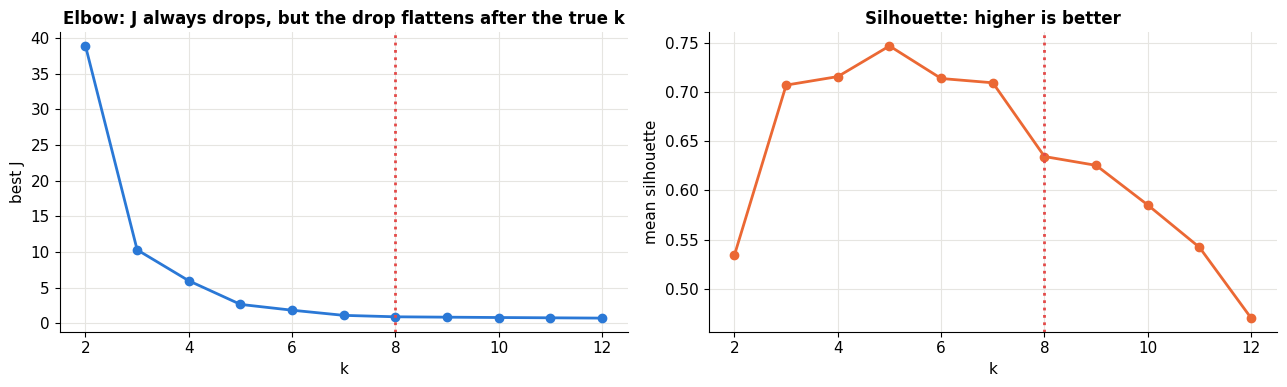

In [13]:
def silhouette(X, labels):
    """Silhouette coefficient of every point, from scratch."""
    D = np.sqrt(sq_dists(X, X)); ks = np.unique(labels); s = np.zeros(len(X))
    for i in range(len(X)):
        own = labels == labels[i]
        if own.sum() == 1: continue                            # singleton cluster: s = 0 by convention
        a = D[i, own].sum() / (own.sum() - 1)                  # exclude the point itself (distance 0)
        b = min(D[i, labels == j].mean() for j in ks if j != labels[i])
        s[i] = (b - a) / max(a, b)
    return s

ks_try = range(2, 13)
fits = {k: kmeans(X8, k, init=kmeans_pp_init(X8, k, seed=0)) for k in ks_try}
for k in ks_try:                                               # a few restarts per k, keep the best
    for s_ in range(1, 8):
        f = kmeans(X8, k, init=kmeans_pp_init(X8, k, seed=s_))
        if f[2] < fits[k][2]: fits[k] = f
sil = {k: silhouette(X8, fits[k][0]) for k in ks_try}
print(f"Silhouette check vs scikit-learn (k=8): {sil[8].mean():.5f} vs {silhouette_score(X8, fits[8][0]):.5f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(ks_try), [fits[k][2] for k in ks_try], "o-", color=C["blue"]); axes[0].axvline(8, color=C["red"], ls=":")
axes[0].set(xlabel="k", ylabel="best J", title="Elbow: J always drops, but the drop flattens after the true k")
axes[1].plot(list(ks_try), [sil[k].mean() for k in ks_try], "o-", color=C["orange"]); axes[1].axvline(8, color=C["red"], ls=":")
axes[1].set(xlabel="k", ylabel="mean silhouette", title="Silhouette: higher is better")
fig.tight_layout(); plt.show()

The data was generated with 8 blobs (red dotted line). The elbow is visible but soft, which is typical: in real data it's often a judgment call. Here some of the 8 blobs overlap, so the silhouette may prefer a smaller $k$ that treats touching blobs as one, which is a reasonable answer too. 🎚️ **Change $k$** and look at the silhouette plot: each horizontal bar is one point's $s(i)$, grouped by cluster.

In [14]:
def plot_k(k=8):
    lab, cen, J_, _ = fits[k]; s = sil[k]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    cm = plt.get_cmap("tab20")
    axes[0].scatter(*X8.T, s=10, c=[cm(l % 20) for l in lab]); axes[0].scatter(*cen.T, marker="X", s=160, c="k", edgecolor="white")
    axes[0].set(title=f"k = {k}:  J = {J_:.2f}", aspect="equal"); axes[0].grid(False)
    y0 = 0
    for j in range(k):
        sj = np.sort(s[lab == j])
        axes[1].fill_betweenx(np.arange(y0, y0 + len(sj)), 0, sj, color=cm(j % 20), alpha=0.85)
        y0 += len(sj) + 8
    axes[1].axvline(s.mean(), color=C["red"], ls="--", label=f"mean silhouette {s.mean():.3f}")
    axes[1].set(xlim=(-0.3, 1), xlabel="silhouette s(i)", yticks=[], title="silhouette plot (one bar per point)"); axes[1].legend(loc="lower right")
    fig.tight_layout(); plt.show()

interact(plot_k, k=IntSlider(value=8, min=2, max=12, description="k"));

At small $k$ the clusters are wide and some points are almost as close to a neighboring cluster as to their own. At large $k$, real blobs get chopped in half, and the halves' points have small or negative silhouettes because the other half of their blob is right next door.

> 🤔 **Question: Is there a "correct" k?**
>
> Only relative to a purpose. Grouping customers for three marketing campaigns means $k = 3$, whatever the elbow says. In image compression (next section), $k$ is a budget: more colors, better quality, bigger file. The elbow, the silhouette, and alternatives like the **gap statistic** (compare $J$ with what you'd get on structureless random data) are guides, not oracles. When the clusters aren't well separated, different criteria will disagree, and that disagreement is itself information.

---
## 8. Image compression by clustering colors

A color image is a grid of pixels, each an (R, G, B) triple, so it's also a **cloud of points in 3-D color space**. Cluster those points into $k$ groups and replace every pixel by its cluster's center color: the image now uses only $k$ colors. This is **color quantization**, and it's ISYE HW1's programming problem. Here we use a photo that ships with scikit-learn.

image 214×320 = 68,480 pixels, each a point in RGB space


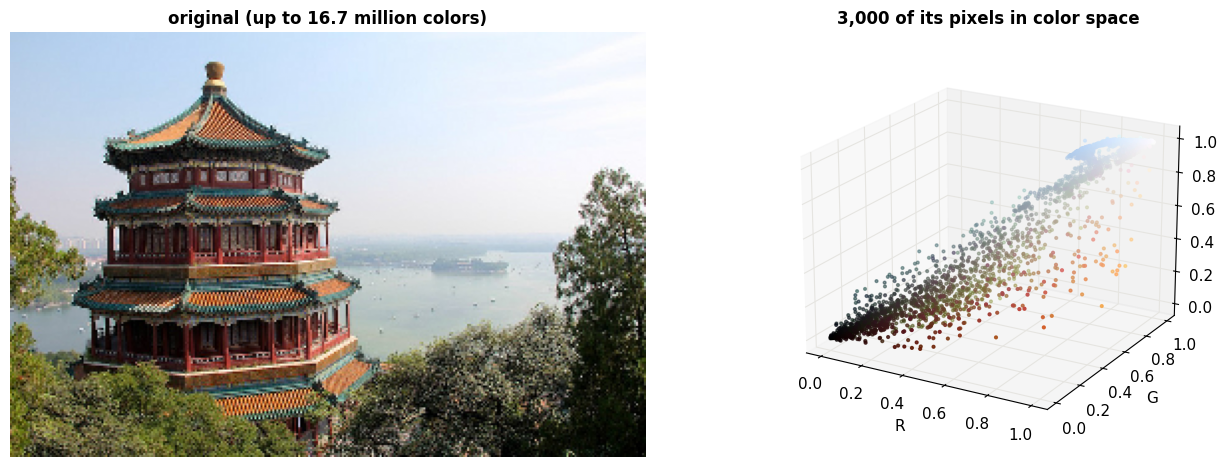

In [15]:
img = load_sample_image("china.jpg")[::2, ::2] / 255.0       # 214 × 320 pixels, RGB in [0, 1]
pixels = img.reshape(-1, 3)
print(f"image {img.shape[0]}×{img.shape[1]} = {len(pixels):,} pixels, each a point in RGB space")

fig = plt.figure(figsize=(14, 4.8))
ax = fig.add_subplot(1, 2, 1); ax.imshow(img); ax.axis("off"); ax.set_title("original (up to 16.7 million colors)")
ax = fig.add_subplot(1, 2, 2, projection="3d")
sub = pixels[np.random.default_rng(0).choice(len(pixels), 3000, replace=False)]
ax.scatter(*sub.T, c=sub, s=4); ax.set(xlabel="R", ylabel="G", zlabel="B", title="3,000 of its pixels in color space")
ax.view_init(20, -60); plt.tight_layout(); plt.show()

The pixels form a few elongated clouds (sky blues, building greys and browns, foliage greens). Now run our from-scratch k-means for several $k$ and record the iterations and runtime, as HW1 asks:

In [16]:
quant, rows = {}, []
for k in [2, 3, 4, 5, 6, 8, 16, 32]:
    t0 = time.time()
    lab, cen, J_, it = kmeans(pixels, k, init=kmeans_pp_init(pixels, k, seed=0), max_iter=100)
    dt = time.time() - t0
    quant[k] = (lab, cen)
    mse = J_ / 3                                               # J is the sum over 3 channels; MSE per channel value
    rows.append(dict(k=k, iterations=it, seconds=round(dt, 2), MSE=f"{mse:.5f}", PSNR_dB=round(10 * np.log10(1 / mse), 1),
                     bits_per_pixel=int(np.ceil(np.log2(k)))))
table = pd.DataFrame(rows); table

,k,iterations,seconds,MSE,PSNR_dB,bits_per_pixel
0,2,7,0.07,0.01972,17.1,1
1,3,20,0.16,0.01016,19.9,2
2,4,62,0.54,0.00701,21.5,2
3,5,23,0.22,0.00526,22.8,3
4,6,57,0.57,0.00428,23.7,3
5,8,39,0.49,0.00324,24.9,3
6,16,82,1.80,0.00180,27.5,4
7,32,72,2.88,0.00097,30.1,5


Iterations grow with $k$ (more centers, more jostling), and so does the cost per iteration (each pixel is compared with $k$ centers), so runtime grows faster than linearly. Quality is measured by **PSNR** (peak signal-to-noise ratio, $10\log_{10}(1/\text{MSE})$; higher is better, and above roughly 30 dB differences are hard to see). Here are the results side by side:

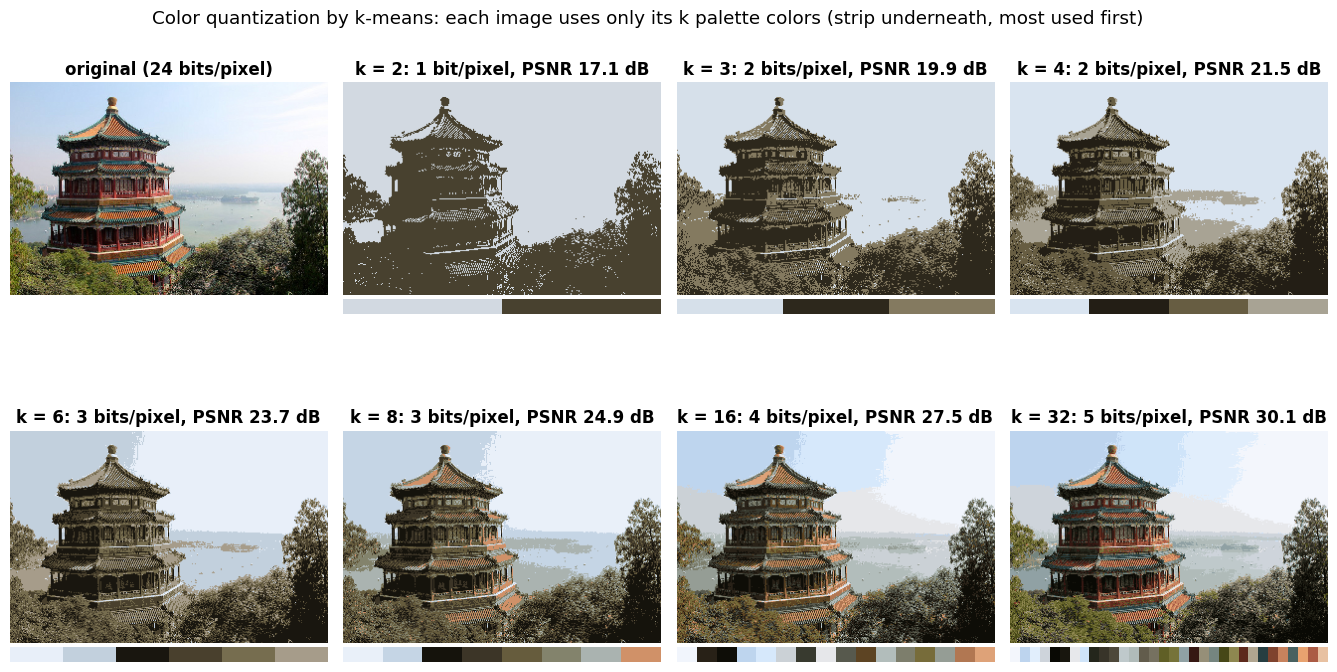

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.6))
panels = [("original", None)] + [(f"k = {k}", k) for k in [2, 3, 4, 6, 8, 16, 32]]
for ax, (name, k) in zip(axes.ravel(), panels):
    if k is None:
        ax.imshow(img); ax.set_title("original (24 bits/pixel)")
    else:
        lab, cen = quant[k]; out = np.clip(cen[lab].reshape(img.shape), 0, 1)
        mse = np.mean((out - img) ** 2); bits = max(1, int(np.ceil(np.log2(k))))
        ax.imshow(out); ax.set_title(f"k = {k}: {bits} bit{'s' if bits > 1 else ''}/pixel, PSNR {10 * np.log10(1 / mse):.1f} dB")
        pal = cen[np.argsort(-np.bincount(lab, minlength=k))]
        ins = ax.inset_axes([0.0, -0.09, 1.0, 0.07]); ins.imshow(pal[None], aspect="auto"); ins.axis("off")
    ax.axis("off")
fig.suptitle("Color quantization by k-means: each image uses only its k palette colors (strip underneath, most used first)", y=0.97)
fig.subplots_adjust(hspace=0.38, wspace=0.05, top=0.9); plt.show()

At $k = 2$ the photo becomes a two-tone poster; by $k = 16$ to $32$ it's close to the original at this size (PSNR approaching 30 dB), while each pixel needs only 4 to 5 bits instead of 24 (about a fifth of the storage, before any further compression). The same trick shows up in GIF images (at most 256 colors) and in vector quantization for speech, and the idea of replacing vectors by the nearest of $k$ "codewords" is how modern image tokenizers (VQ-VAE) turn images into discrete tokens.

> 🤔 **Question: How would you choose k here in a principled way?** (HW1)
>
> Treat it as a trade-off curve: plot reconstruction error (or PSNR) against $k$ or against bits per pixel, and pick the knee, or set a quality target (say PSNR ≥ 30 dB) and take the smallest $k$ that meets it. Squared error in RGB doesn't perfectly match human perception, so a perceptual color space (like CIELAB) or a perceptual metric gives better choices in practice. Try both in the exercises.

---
## 9. Generalized k-means: other distances, other centers

Vanilla k-means makes three assumptions (ISYE W2): **squared Euclidean distance is meaningful**, **clusters are compact and roughly spherical**, and **the mean is a good representative**. Generalized k-means keeps the alternating structure but lets you swap the distance $d$ (ISYE W2, CX lecture 16):

$$\text{assign: } \pi(i) = \arg\min_j d(x^i, c^j), \qquad \text{update: } c^j = \arg\min_{v}\sum_{i:\pi(i)=j} d(x^i, v)$$

The update must now minimize **the new distance**, and the answer is no longer the mean. For the **Manhattan distance** $d(x, v) = \sum_\ell |x_\ell - v_\ell|$, the problem separates by coordinate, and $\sum_i |x_\ell^i - v_\ell|$ is minimized by the **median** (moving $v_\ell$ past a data point changes the slope by 2, so the minimum is where half the points are on each side). That's **k-medians** (HW1 Q6 part 2).

The median is **robust**: one wild point barely moves it, while it can drag a mean far away. Two tight clusters plus a handful of extreme outliers:

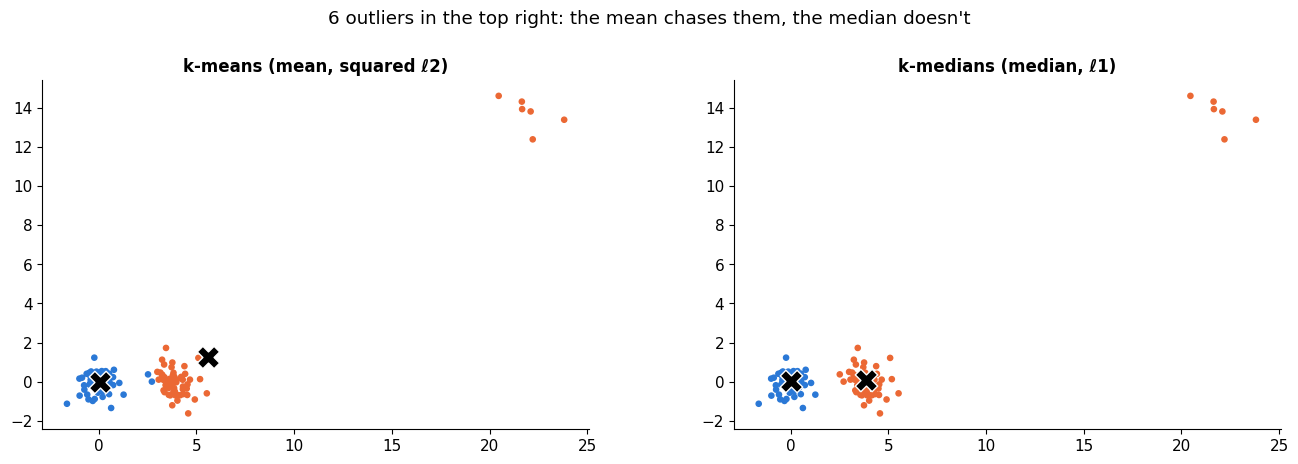

k-means centers:
 [[ 0.06 -0.03]
 [ 5.6   1.25]] 
k-medians centers:
 [[0.01 0.04]
 [3.84 0.08]]


In [18]:
def kmedians(X, k, init, max_iter=100):
    centers = np.array(init, float).copy(); labels = None
    for it in range(max_iter):
        D = np.abs(X[:, None, :] - centers[None]).sum(-1)       # Manhattan distance to each center
        new = D.argmin(1)
        if labels is not None and np.array_equal(new, labels): break
        labels = new
        for j in range(k):
            if np.any(labels == j): centers[j] = np.median(X[labels == j], axis=0)
    return labels, centers

r_ = np.random.default_rng(1)
A = r_.normal([0, 0], 0.6, (60, 2)); B = r_.normal([4, 0], 0.6, (60, 2)); out = r_.normal([22, 14], 1.0, (6, 2))
Xo = np.vstack([A, B, out])
init = np.array([[0.5, 0.5], [3.5, -0.5]])
lab_mean, cen_mean, _, _ = kmeans(Xo, 2, init=init); lab_med, cen_med = kmedians(Xo, 2, init)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, lab, cen, name in [(axes[0], lab_mean, cen_mean, "k-means (mean, squared ℓ2)"), (axes[1], lab_med, cen_med, "k-medians (median, ℓ1)")]:
    ax.scatter(*Xo.T, s=14, c=[C["blue"] if l == 0 else C["orange"] for l in lab])
    ax.scatter(*cen.T, marker="X", s=260, c="k", edgecolor="white", zorder=5)
    ax.set(title=name, aspect="equal"); ax.grid(False)
fig.suptitle("6 outliers in the top right: the mean chases them, the median doesn't", y=1.02); fig.tight_layout(); plt.show()
print("k-means centers:\n", cen_mean.round(2), "\nk-medians centers:\n", cen_med.round(2))

Both methods find the two real clusters, but look at the right-hand centers. The outliers get assigned to the right cluster, and because the mean weighs every point equally, six points 20 units away drag the k-means center from about (4, 0) to (5.6, 1.25), outside its own cluster. The median of that cluster barely notices them and stays at (3.8, 0.1). With more outliers, or a different start, k-means can do worse still: since squared error grows fast with distance, it's often cheaper to spend a whole center on a handful of far-away points and merge two real clusters.

### ℓ2 vs. ℓ1 on handwritten digits

HW1's bonus question runs both versions on MNIST and compares **purity**: give each cluster the label of its most common digit and count how many points that gets right. Here's the same experiment on the scikit-learn digits, with five k-means++ starts each:

In [19]:
rows = []
for s in range(5):
    init = kmeans_pp_init(Xd, 10, seed=s)
    lab2, _, _, _ = kmeans(Xd, 10, init=init)
    lab1, _ = kmedians(Xd, 10, init)
    rows.append({"start": s, "k-means (ℓ2², mean) purity": round(purity(lab2, yd), 3), "k-medians (ℓ1, median) purity": round(purity(lab1, yd), 3)})
res = pd.DataFrame(rows).set_index("start"); display(res)
print("averages:", res.mean().round(3).to_dict())

,"k-means (ℓ2², mean) purity","k-medians (ℓ1, median) purity"
start,,
0,0.789,0.712
1,0.730,0.779
2,0.788,0.779
3,0.789,0.712
4,0.715,0.715


averages: {'k-means (ℓ2², mean) purity': 0.762, 'k-medians (ℓ1, median) purity': 0.739}


Neither wins consistently: both land around 0.7 to 0.8, and the starting point moves purity more than the choice of distance does. On clean, bounded data like pixel intensities there are no wild outliers for the median to resist, so k-medians' robustness doesn't buy much. (Pixels also make medians awkward: the median of many 0/1-ish values is often exactly 0 or 1, so the "center" images look blocky.)

### k-medoids: centers must be real data points

What if you can compute distances but **can't average**? You can't take the mean of three words. **k-medoids** restricts each center to be one of the cluster's own points: the one with the smallest total distance to the others (the *medoid*). It needs nothing but a distance matrix, so it works with any distance at all. Let's cluster misspelled words with edit distance:

In [20]:
words = ["color", "colour", "colr", "collor", "coler", "kolor",
         "receive", "recieve", "receve", "recive", "reseive",
         "separate", "seperate", "separete", "seprate", "separat", "sepparate"]
Dw = np.array([[edit_distance(a, b) for b in words] for a in words])

def kmedoids(D, k, init_idx, max_iter=50):
    med = list(init_idx)
    for _ in range(max_iter):
        lab = D[:, med].argmin(1)
        new = [np.flatnonzero(lab == j)[D[np.ix_(lab == j, lab == j)].sum(1).argmin()] for j in range(k)]
        if new == med: break
        med = new
    return D[:, med].argmin(1), med

lab_w, med_w = kmedoids(Dw, 3, init_idx=[0, 1, 2])            # deliberately bad start: three spellings of "color"
for j, m in enumerate(med_w):
    print(f"cluster {j}  (medoid '{words[m]}'):  " + ", ".join(w for w, l in zip(words, lab_w) if l == j))

cluster 0  (medoid 'separate'):  separate, seperate, separete, seprate, separat, sepparate
cluster 1  (medoid 'color'):  color, colour, colr, collor, coler, kolor
cluster 2  (medoid 'receive'):  receive, recieve, receve, recive, reseive


Even from a bad start (all three initial medoids were spellings of "color"), the alternating steps recover the three intended words, and each medoid is the most "central" spelling. This is how you cluster DNA sequences, user sessions, or anything else where only a distance makes sense.

---
## 10. Where k-means fails

The assign-to-nearest-center rule means every k-means cluster is a **Voronoi cell**: a convex region bounded by perpendicular bisectors. And the objective rewards balanced, round, equal-variance groups. When the true clusters don't look like that, k-means gets them wrong, however well you initialize:

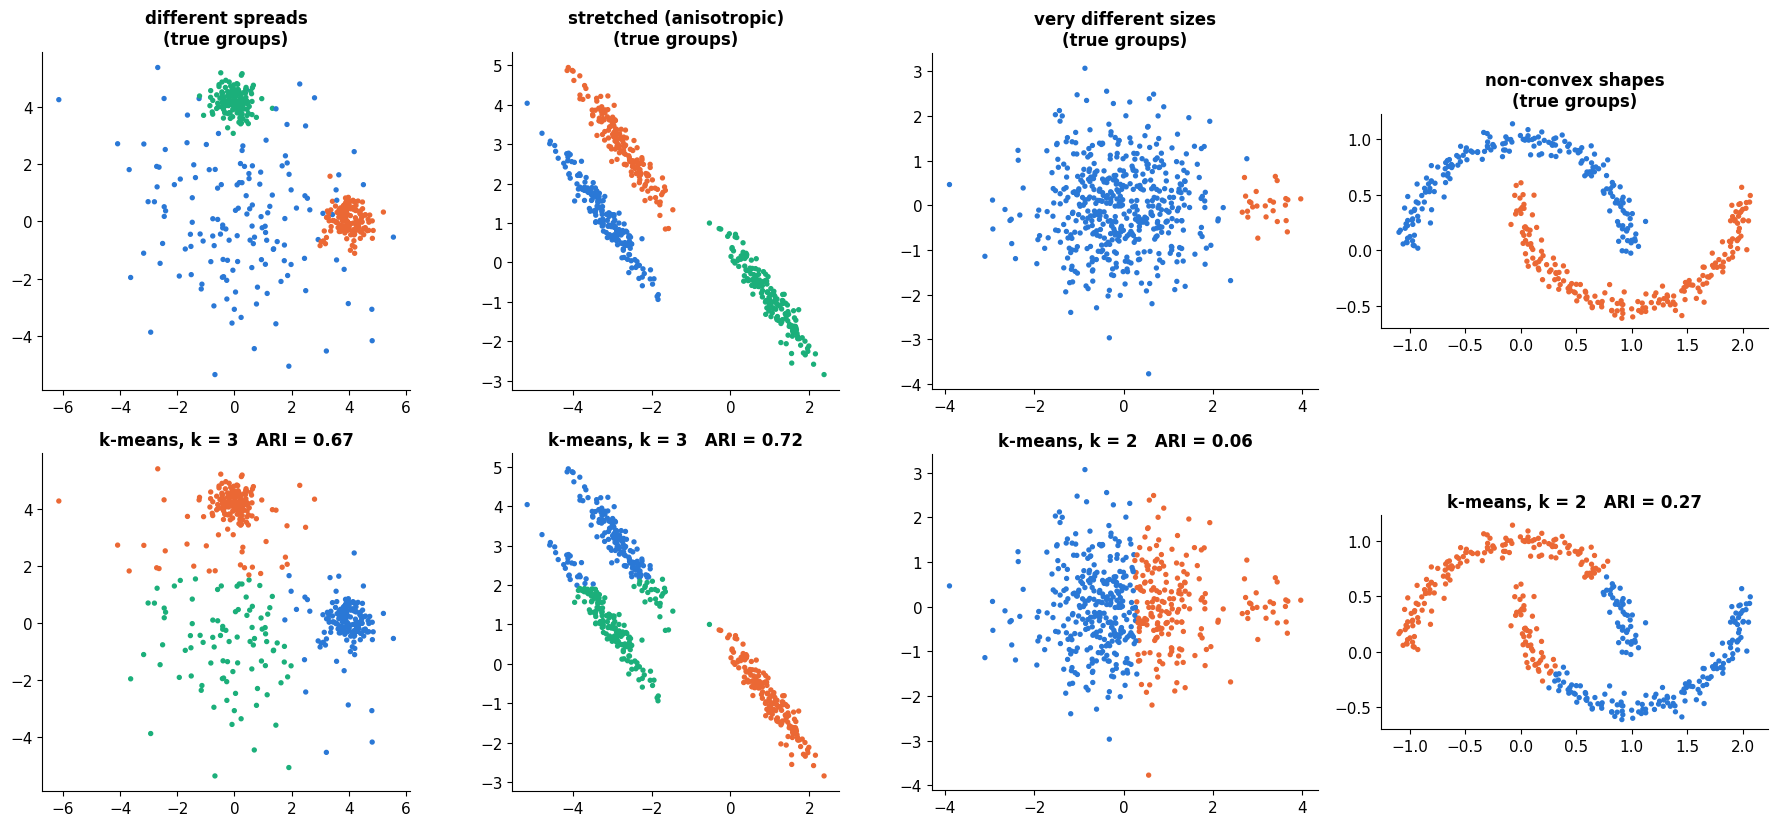

In [21]:
r_ = np.random.default_rng(0)
cases = {}
Xa, ya = make_blobs(450, centers=[(0, 0), (4, 0), (0, 4.2)], cluster_std=[2.2, 0.4, 0.4], random_state=1); cases["different spreads"] = (Xa, ya, 3)
Xs, ys = make_blobs(500, centers=3, cluster_std=0.8, random_state=170); Xs = Xs @ np.array([[0.6, -0.64], [-0.41, 0.85]]); cases["stretched (anisotropic)"] = (Xs, ys, 3)
Xu = np.vstack([r_.normal([0, 0], 1.0, (500, 2)), r_.normal([3.2, 0], 0.4, (25, 2))]); yu = np.r_[np.zeros(500, int), np.ones(25, int)]; cases["very different sizes"] = (Xu, yu, 2)
Xm, ym = make_moons(400, noise=0.06, random_state=0); cases["non-convex shapes"] = (Xm, ym, 2)

fig, axes = plt.subplots(2, 4, figsize=(18, 8.4))
for col, (name, (X_, y_, k)) in enumerate(cases.items()):
    labk = KMeans(k, n_init=10, random_state=0).fit_predict(X_)
    for row, (lab, title) in enumerate([(y_, f"{name}\n(true groups)"), (labk, f"k-means, k = {k}   ARI = {adjusted_rand_score(y_, labk):.2f}")]):
        ax = axes[row, col]; ax.scatter(*X_.T, s=8, c=[pal8[l] for l in lab]); ax.set(title=title, aspect="equal"); ax.grid(False)
fig.tight_layout(); plt.show()

(ARI, the adjusted Rand index, scores agreement with the true groups: 1 is perfect, 0 is chance level; see section 13.)

- **Different spreads:** k-means puts boundaries at the bisectors between centers, so it hands the edge of the wide cluster to its tight neighbors.
- **Stretched clusters:** squared Euclidean distance assumes round clusters; it cuts across the long axes.
- **Different sizes:** splitting the big cluster in half lowers $J$ more than giving the small group its own center.
- **Non-convex shapes:** no straight boundary can separate two interlocking moons.

The first three are fixed by allowing each cluster its own shape and size: that's the **Gaussian mixture model** (notebook 15), of which k-means turns out to be a special case. The fourth needs a different notion of cluster altogether: connectivity. The rest of this notebook covers methods that use it.

---
## 11. Hierarchical clustering

Instead of one partition into $k$ groups, **hierarchical clustering** builds a whole **tree** of nested partitions, from $m$ singletons up to one cluster containing everything. You choose $k$ afterwards by cutting the tree (ISYE W2).

**Agglomerative (bottom-up) clustering:**

1. Start with each point in its own cluster.
2. Find the **closest pair of clusters** and merge them.
3. Repeat until one cluster remains.

"Closest pair of clusters" needs a **linkage**: a distance between *sets* of points.

| Linkage | $D(g_1, g_2)$ | Merges two clusters when… |
|---|---|---|
| **Single** | $\min_{x\in g_1, y\in g_2} d(x,y)$ | *any* one pair of points is close |
| **Complete** | $\max_{x\in g_1, y\in g_2} d(x,y)$ | *all* pairs are close |
| **Average** | $\frac{1}{|g_1||g_2|}\sum_{x\in g_1}\sum_{y\in g_2} d(x,y)$ | the average pair is close |
| **Ward** | increase in total within-cluster variance | merging costs the least k-means objective |

Let's run it by hand on ISYE's 11 points on a line:

In [22]:
pts = np.array([1, 2, 3.1, 4, 4.9, 5.9, 6.9, 8, 9, 10, 11])

def agglomerative(X, linkage_="single"):
    """Naive agglomerative clustering. Returns the merge list [(cluster_a, cluster_b, distance, new_size)] in scipy's format."""
    X = X.reshape(len(X), -1); m = len(X)
    D = np.sqrt(sq_dists(X, X))
    clusters = {i: [i] for i in range(m)}; merges = []; next_id = m
    agg = {"single": np.min, "complete": np.max, "average": np.mean}[linkage_]
    while len(clusters) > 1:
        ids = list(clusters); best = (np.inf, None, None)
        for a in range(len(ids)):
            for b in range(a + 1, len(ids)):
                d = agg(D[np.ix_(clusters[ids[a]], clusters[ids[b]])])
                if d < best[0] - 1e-12: best = (d, ids[a], ids[b])
        d, i, j = best
        clusters[next_id] = clusters.pop(i) + clusters.pop(j)
        merges.append([i, j, d, len(clusters[next_id])]); next_id += 1
    return np.array(merges, float)

Z_ours = agglomerative(pts, "single")
names = {i: f"{p:g}" for i, p in enumerate(pts)}
for step, (a, b, d, size) in enumerate(Z_ours[:6], 1):
    names[len(pts) + step - 1] = "{" + names[int(a)] + ", " + names[int(b)] + "}"
    print(f"merge {step}: {names[int(a)]:>14s}  +  {names[int(b)]:<14s} at distance {d:.2f}")
print("...")
Z_scipy = linkage(pts.reshape(-1, 1), "single")
print("merge heights match scipy:", np.allclose(np.sort(Z_ours[:, 2]), np.sort(Z_scipy[:, 2])))

merge 1:            3.1  +  4              at distance 0.90
merge 2:            4.9  +  {3.1, 4}       at distance 0.90
merge 3:              1  +  2              at distance 1.00
merge 4:            5.9  +  6.9            at distance 1.00
merge 5:              8  +  9              at distance 1.00
merge 6:             10  +  11             at distance 1.00
...
merge heights match scipy: True


The first merge is 3.1 and 4 (distance 0.9; strictly, 4 − 3.1 = 0.8999… in floating point, which beats 4.9 − 4 = 0.9000…, a reminder that exact ties are broken by accident). Then 4.9 joins them, and so on. The **dendrogram** records every merge as a horizontal bar at the height of the merge distance:

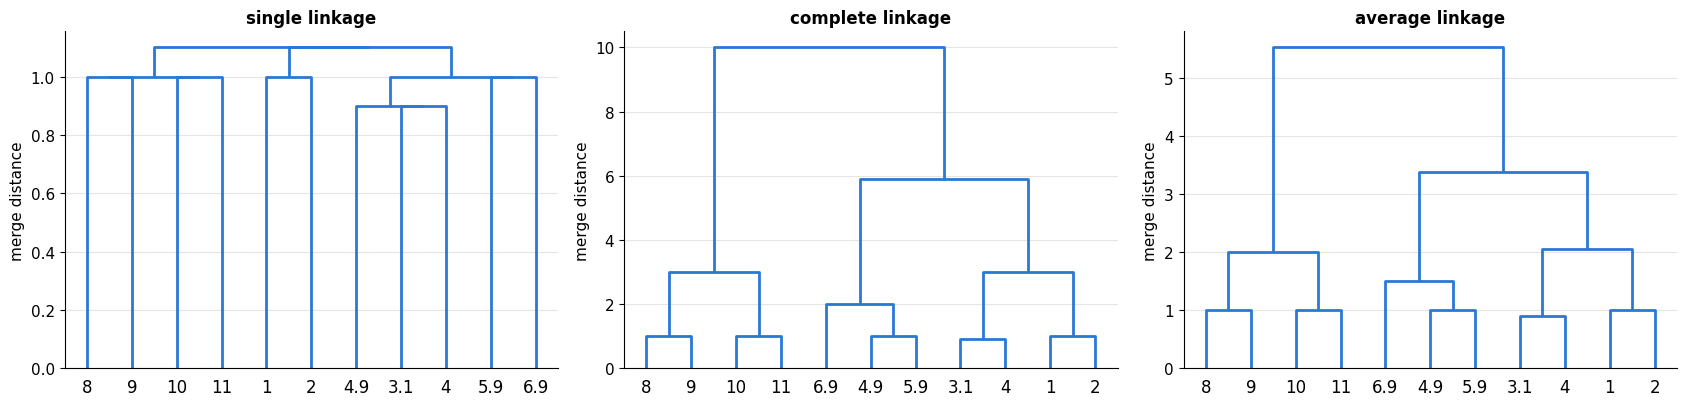

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, lk in zip(axes, ["single", "complete", "average"]):
    Z = agglomerative(pts, lk)
    dendrogram(Z, labels=[f"{p:g}" for p in pts], ax=ax, color_threshold=0, above_threshold_color=C["blue"])
    ax.set(title=f"{lk} linkage", ylabel="merge distance"); ax.grid(axis="x")
fig.tight_layout(); plt.show()

With single linkage, the points are almost evenly spaced (gaps of 0.9 to 1.1), so the tree is a long **chain**: each new merge adds one neighbor at nearly the same height. Complete linkage measures the *farthest* pair, so big clusters look far apart, and it builds a more **balanced** tree.

> 🤔 **Question: What does the height at which two branches merge represent?** (ISYE W2)
>
> The **linkage distance** between the two clusters at the moment they merged. For single, complete, average, and Ward linkage these heights never decrease as you go up, so cutting the tree with a horizontal line at height $h$ gives a valid clustering: every cluster below the line has internal merge distances under $h$. (Some linkages, like *centroid* linkage, can produce "inversions" where a later merge is lower, which makes cutting ambiguous.) A long vertical stretch with no merges means the clusters below it are well separated: a natural place to cut.

### Cutting the tree

🎚️ **Move the cut height**: every branch the red line crosses becomes one cluster.

In [24]:
Xh, yh = make_blobs(60, centers=[(0, 0), (4, 0.5), (2, 4), (7, 4)], cluster_std=[0.6, 0.6, 0.8, 0.5], random_state=2)
Zh = linkage(Xh, "average")

def plot_cut(height=2.5):
    lab = fcluster(Zh, t=height, criterion="distance")
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1.5, 1]))
    dendrogram(Zh, ax=axes[0], color_threshold=height, no_labels=True, above_threshold_color=C["muted"])
    axes[0].axhline(height, color=C["red"], ls="--", lw=2)
    axes[0].set(title=f"average linkage dendrogram: cut at {height:.1f} → {lab.max()} clusters", ylabel="merge distance"); axes[0].grid(False)
    cm = plt.get_cmap("tab10")
    axes[1].scatter(*Xh.T, s=40, c=[cm((l - 1) % 10) for l in lab]); axes[1].set(aspect="equal", title="clusters in the data"); axes[1].grid(False)
    fig.tight_layout(); plt.show()

interact(plot_cut, height=FloatSlider(value=2.5, min=0.3, max=8.0, step=0.1, description="cut height"));

One tree, every resolution: a low cut gives many small clusters, a high cut gives few. The long vertical stretch in the dendrogram (roughly between heights 2 and 4) is where four clusters are stable over a wide range of cuts: a natural place to cut.

### Linkage matters

The same algorithm with different linkages finds very different structure:

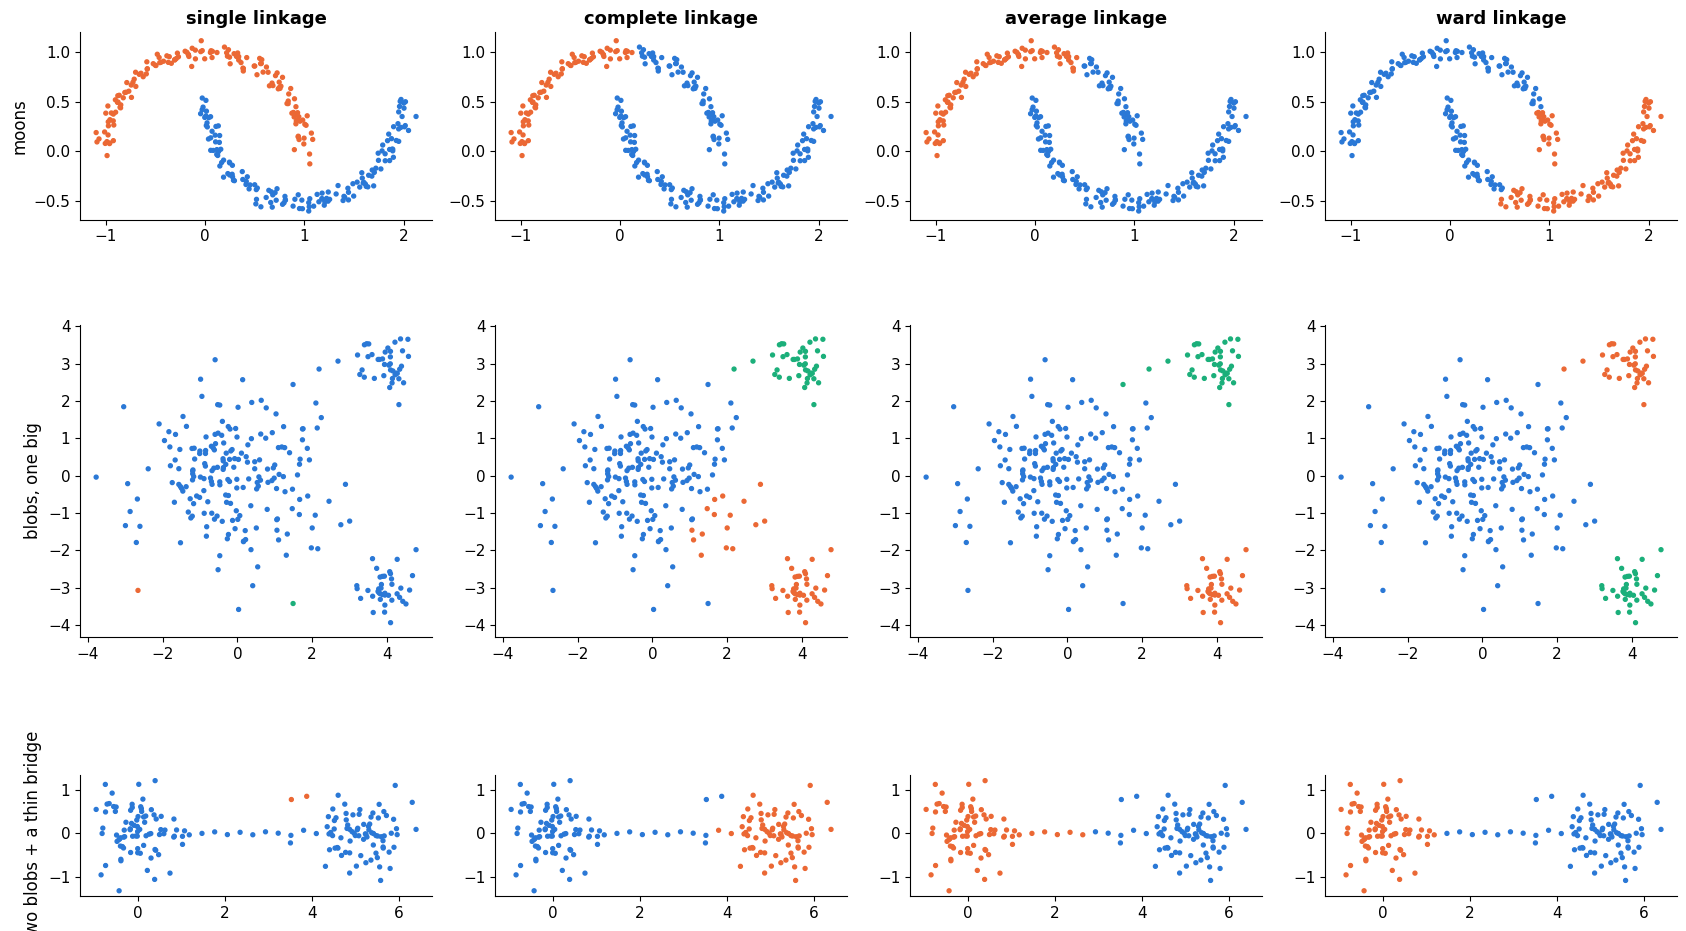

In [25]:
r_ = np.random.default_rng(4)
bridge = np.vstack([r_.normal([0, 0], 0.5, (80, 2)), r_.normal([5, 0], 0.5, (80, 2)), np.column_stack([np.linspace(0.6, 4.4, 14), r_.normal(0, 0.05, 14)])])
data_sets = {"moons": make_moons(300, noise=0.05, random_state=0)[0],
             "blobs, one big": np.vstack([r_.normal([0, 0], 1.2, (200, 2)), r_.normal([4, 3], 0.4, (40, 2)), r_.normal([4, -3], 0.4, (40, 2))]),
             "two blobs + a thin bridge": bridge}
fig, axes = plt.subplots(3, 4, figsize=(17, 11))
for row, (dname, X_) in enumerate(data_sets.items()):
    k = 3 if dname == "blobs, one big" else 2
    for col, lk in enumerate(["single", "complete", "average", "ward"]):
        lab = AgglomerativeClustering(n_clusters=k, linkage=lk).fit_predict(X_)
        ax = axes[row, col]; ax.scatter(*X_.T, s=8, c=[pal8[l] for l in lab]); ax.set(aspect="equal"); ax.grid(False)
        if row == 0: ax.set_title(f"{lk} linkage", fontsize=13)
        if col == 0: ax.set_ylabel(dname, fontsize=12)
fig.tight_layout(); plt.show()

- **Single linkage** follows connectivity: it recovers the moons perfectly. But that same property makes it **chain**: a thin bridge of points is enough to fuse two blobs into one cluster, leaving a few stray points as the other "cluster".
  You can see a milder version in the middle row: single linkage puts nearly everything in one cluster and gives the other two "clusters" to single stray points.
- **Complete and average linkage** prefer compact groups; they cut the moons with a straight-ish line, but resist chaining.
- **Ward linkage** merges whatever increases the k-means objective least, so it behaves much like k-means.

Hierarchical clustering also has a cost: the naive algorithm compares all pairs of clusters at every merge ($O(m^3)$ time, $O(m^2)$ memory for the distance matrix), so it's practical for thousands of points, not millions. **Divisive** (top-down) clustering runs the other way: start with one cluster and repeatedly split the least cohesive one (CX lecture 16).

---
## 12. Beyond k-means: density and graphs

Two widely used methods handle non-convex clusters directly.

### DBSCAN: clusters are dense regions

**DBSCAN** (Ester et al., 1996) defines a cluster as a region where points are packed densely, separated by sparse regions. Two parameters: a radius $\varepsilon$ and a count `min_pts`.

- A **core point** has at least `min_pts` points (itself included) within distance $\varepsilon$.
- Core points within $\varepsilon$ of each other belong to the same cluster; grow each cluster by repeatedly adding neighbors of its core points.
- Non-core points reached from a cluster are **border** points; points reached from no cluster are **noise**.

It finds the number of clusters by itself and labels outliers as noise.

In [26]:
def dbscan(X, eps, min_pts):
    D = np.sqrt(sq_dists(X, X)); nbrs = [np.flatnonzero(row <= eps) for row in D]
    core = np.array([len(n) >= min_pts for n in nbrs]); labels = np.full(len(X), -1); cid = 0
    for i in range(len(X)):
        if not core[i] or labels[i] != -1: continue
        labels[i] = cid; stack = [i]                           # flood-fill from an unvisited core point
        while stack:
            p = stack.pop()
            for q in nbrs[p]:
                if labels[q] == -1:
                    labels[q] = cid
                    if core[q]: stack.append(q)                # only core points keep spreading the cluster
        cid += 1
    return labels, core

Xdb = np.vstack([make_moons(300, noise=0.07, random_state=1)[0], np.random.default_rng(2).uniform([-1.5, -1], [2.5, 1.5], (25, 2))])
ours, _ = dbscan(Xdb, 0.2, 5); sk = DBSCAN(eps=0.2, min_samples=5).fit_predict(Xdb)
print(f"agreement with scikit-learn's DBSCAN (ARI): {adjusted_rand_score(ours, sk):.3f}; same noise points: {np.array_equal(ours == -1, sk == -1)}")

def plot_dbscan(eps=0.2, min_pts=5):
    lab, core = dbscan(Xdb, eps, min_pts)
    fig, ax = plt.subplots(figsize=(8, 4.6))
    noise = lab == -1
    cm = plt.get_cmap("tab10")
    ax.scatter(*Xdb[noise].T, s=25, marker="x", color=C["muted"], label=f"noise ({noise.sum()})")
    ax.scatter(*Xdb[~noise & core].T, s=22, c=[cm(l % 10) for l in lab[~noise & core]])
    ax.scatter(*Xdb[~noise & ~core].T, s=22, facecolors="none", edgecolors=[cm(l % 10) for l in lab[~noise & ~core]], label="border points (hollow)")
    ax.set(aspect="equal", title=f"DBSCAN, ε = {eps:.2f}, min_pts = {min_pts}:  {lab.max() + 1} clusters"); ax.legend(loc="upper right", fontsize=9); ax.grid(False)
    plt.show()

interact(plot_dbscan, eps=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.01, description="ε"),
         min_pts=IntSlider(value=5, min=2, max=20, description="min_pts"));

agreement with scikit-learn's DBSCAN (ARI): 1.000; same noise points: True


Around ε = 0.2 DBSCAN finds both moons and flags the scattered points as noise. Too small an ε and the moons crumble into fragments (and almost everything is noise); too large and everything merges. DBSCAN struggles when clusters have **different densities**, since one ε can't fit both.

### Spectral clustering: clusters are well-connected parts of a graph

**Spectral clustering** turns the data into a **similarity graph**: connect each point to its nearest neighbors, with edge weights $W_{ij}$ that are large for close points. A good clustering cuts few edges between groups. Finding the best cut is hard, but a relaxation has a clean answer in terms of eigenvectors (notebook 01): form the **graph Laplacian** $L = D - W$ (with $D$ the diagonal matrix of node degrees) and take the eigenvectors of its smallest eigenvalues. They give each point new coordinates in which the clusters are **compact blobs**, and plain k-means finishes the job.

Why does this work? $f^\top L f = \frac12\sum_{ij}W_{ij}(f_i - f_j)^2$, so an eigenvector with a small eigenvalue is a function on the points that **changes little across edges**: it's nearly constant on each well-connected piece. (If the graph had truly disconnected pieces, the indicator vector of each piece would have eigenvalue exactly 0.)

smallest Laplacian eigenvalues: [0.     0.     0.0032 0.0034 0.0052 0.0064]


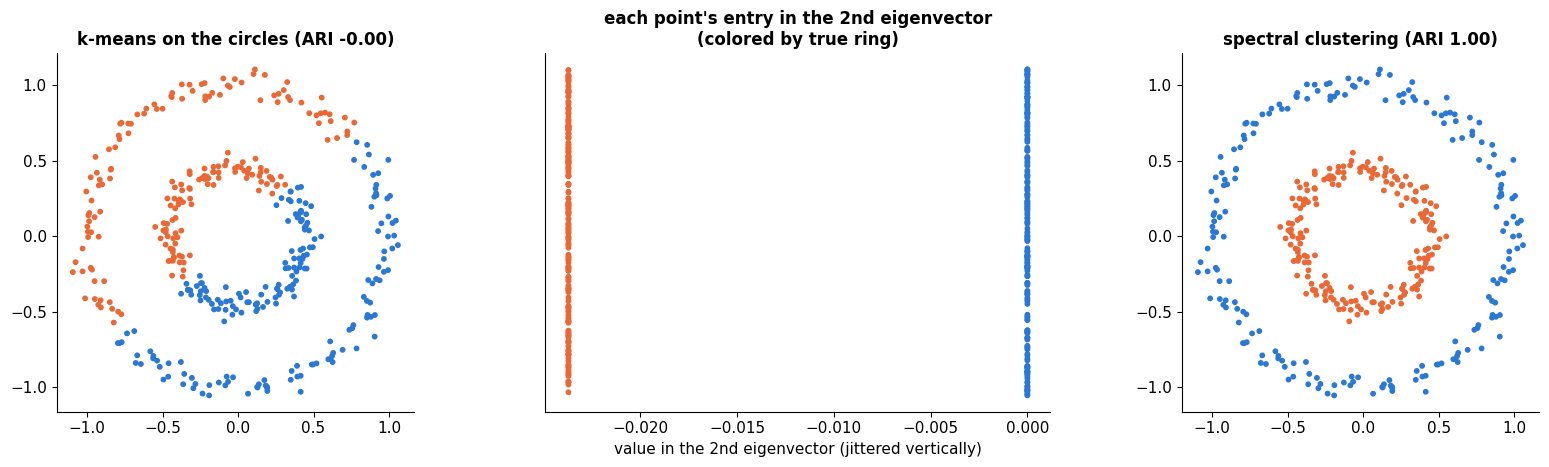

In [27]:
def spectral(X, k, n_neighbors=10, seed=0):
    D2 = sq_dists(X, X); m = len(X)
    sigma2 = np.median(np.sort(D2, 1)[:, n_neighbors])         # bandwidth from typical k-NN distance
    W = np.exp(-D2 / sigma2)
    keep = np.zeros_like(W, bool); idx = np.argsort(D2, 1)[:, 1:n_neighbors + 1]
    keep[np.repeat(np.arange(m), n_neighbors), idx.ravel()] = True; keep |= keep.T   # symmetric k-NN graph
    W = np.where(keep, W, 0.0)
    deg = W.sum(1); Dm = 1 / np.sqrt(deg)
    L_sym = np.eye(m) - Dm[:, None] * W * Dm[None, :]           # normalized Laplacian I - D^-1/2 W D^-1/2
    vals, vecs = np.linalg.eigh(L_sym)
    U = vecs[:, :k]; U = U / np.linalg.norm(U, axis=1, keepdims=True)   # embedding (Ng–Jordan–Weiss normalization)
    lab, _, _, _ = kmeans(U, k, init=kmeans_pp_init(U, k, seed=seed))
    F = vecs[:, :k] * Dm[:, None]                               # same eigenvectors rescaled: piecewise constant on components
    return lab, F, vals[:6]

Xc, yc = make_circles(400, factor=0.45, noise=0.05, random_state=0)
lab_sp, F, vals = spectral(Xc, 2)
lab_km = KMeans(2, n_init=10, random_state=0).fit_predict(Xc)
print("smallest Laplacian eigenvalues:", np.abs(vals).round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(*Xc.T, s=10, c=[pal8[l] for l in lab_km]); axes[0].set(title=f"k-means on the circles (ARI {adjusted_rand_score(yc, lab_km):.2f})", aspect="equal")
f2 = F[:, 1]; jit = np.random.default_rng(0).uniform(-1, 1, len(f2))
axes[1].scatter(f2, jit, s=10, c=[pal8[l] for l in yc]); axes[1].set(yticks=[], xlabel="value in the 2nd eigenvector (jittered vertically)",
                                                                     title="each point's entry in the 2nd eigenvector\n(colored by true ring)")
axes[2].scatter(*Xc.T, s=10, c=[pal8[l] for l in lab_sp]); axes[2].set(title=f"spectral clustering (ARI {adjusted_rand_score(yc, lab_sp):.2f})", aspect="equal")
for ax in axes: ax.grid(False)
fig.tight_layout(); plt.show()

In the original space no straight boundary separates the rings, and k-means cuts them in half. The middle panel shows each point's entry in the second eigenvector: every point of the inner ring gets one value and every point of the outer ring another, so the rings collapse to two spikes. The printout explains why: the two smallest eigenvalues are 0 (to rounding), which happens exactly when the neighbor graph falls into **two disconnected pieces**. With 10 neighbors per point, no point's neighbors reach across the gap between the rings, so each ring's indicator vector is an eigenvector with eigenvalue 0. On real data the pieces are usually only *nearly* disconnected (a few weak edges between them), the eigenvalues are small but nonzero, and the spikes become tight clumps; k-means on the embedding still separates them easily.

---
## 13. Evaluating a clustering

**Without labels** (the usual situation), you can only use **internal** criteria: the objective $J$, the silhouette, stability across restarts or subsamples (does the clustering change much if you perturb the data?), and, most importantly, whether the clusters make sense to someone who knows the domain.

**With labels** (benchmarks, sanity checks), **external** criteria compare clusters with known classes:

- **Purity** (HW1 Q6): label each cluster by its majority class, count correct points.
- **Adjusted Rand index (ARI)**: of all pairs of points, how often do the clustering and the labels agree on "same group" vs. "different group", corrected so that random labels score 0 on average and perfect agreement scores 1.

Purity has a blind spot. Watch what happens as $k$ grows on the digits:

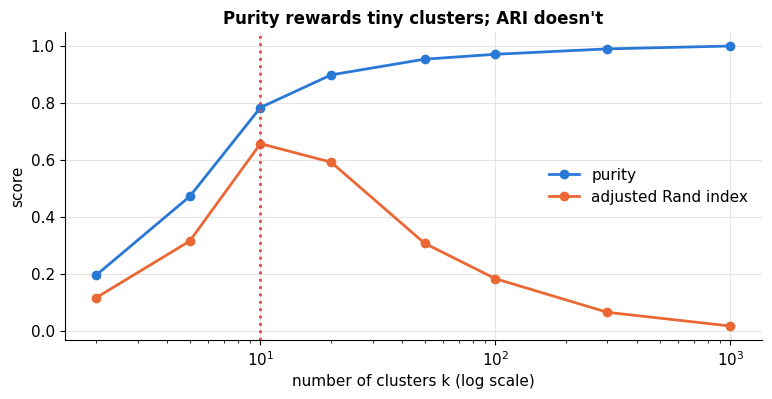

,k,purity,ARI
0,2,0.196,0.117
1,5,0.472,0.315
2,10,0.784,0.657
3,20,0.899,0.592
4,50,0.954,0.307
5,100,0.971,0.183
6,300,0.990,0.065
7,1000,1.000,0.017


In [28]:
rows = []
for k in [2, 5, 10, 20, 50, 100, 300, 1000]:
    lab = KMeans(k, n_init=3, random_state=0).fit_predict(Xd)
    rows.append(dict(k=k, purity=purity(lab, yd), ARI=adjusted_rand_score(yd, lab)))
ev = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(ev.k, ev.purity, "o-", color=C["blue"], label="purity"); ax.semilogx(ev.k, ev.ARI, "o-", color=C["orange"], label="adjusted Rand index")
ax.axvline(10, color=C["red"], ls=":"); ax.set(xlabel="number of clusters k (log scale)", ylabel="score", title="Purity rewards tiny clusters; ARI doesn't")
ax.legend(); plt.show()
ev.round(3)

Purity keeps climbing toward 1 as clusters shrink: with one point per cluster, every cluster is trivially "pure". ARI peaks near the true number of classes and then falls, because tiny clusters split pairs of same-digit images that should be together. So use purity only to compare clusterings with the **same** $k$ (as HW1 does), and prefer ARI (or normalized mutual information) otherwise.

---
## 14. Summary

| Method | Cluster = | Needs $k$? | Shapes it finds | Cost | Watch out for |
|---|---|---|---|---|---|
| **k-means** | points nearest a mean | yes | convex, round, similar size | $O(mkd)$ per iteration | initialization, scaling, outliers |
| **k-medians / k-medoids** | points nearest a median / a data point | yes | convex | more per iteration | k-medoids works with *any* distance |
| **Hierarchical** | branch of a merge tree | no (cut later) | depends on linkage | $O(m^2)$ memory | single linkage chains |
| **DBSCAN** | dense connected region | no | arbitrary | about $O(m\log m)$ with an index | one density for all clusters |
| **Spectral** | well-connected piece of a graph | yes | arbitrary (connected) | eigenvectors of an $m\times m$ matrix | graph construction, scale |

**The big lessons:** representation and distance come first (section 2 changed the answer without touching the algorithm); k-means is block coordinate descent on the within-cluster variance and always converges, but only to a local minimum (so use k-means++ and restarts); $k$ is chosen by trade-off, not by minimizing $J$; and every method has a built-in notion of what a cluster *is*. Next, the **Gaussian mixture model** (notebook 15) turns k-means into a probabilistic model, which gives soft assignments, clusters with their own shapes, and the EM algorithm.

### ✏️ Exercises

1. Prove that the update step's mean minimizes $\sum_i \|x^i - c\|^2$, and that for one coordinate the median minimizes $\sum_i |x_i - v|$. What minimizes $\max_i |x_i - v|$?
2. Run section 5's experiment with $k = 8$ but blobs that are further apart (`cluster_std=0.4`). Does random initialization get better or worse? Why?
3. Redo the image compression in **CIELAB** color space (`skimage.color.rgb2lab`), converting the centers back to RGB for display. At the same $k$, which looks better to you, and which has the higher RGB PSNR?
4. Implement **mini-batch k-means** (update centers using random batches of 1,000 pixels with a decaying step size). How close does it get to full k-means on the photo, and how much faster is it?
5. Show that for 0/1 vectors, squared Euclidean distance equals Hamming distance. Then design a dataset with one numeric column and two one-hot columns where unscaled Euclidean distance ignores the categories completely.
6. Compute the single-linkage dendrogram of the 11 points by hand for the first four merges and check it against `agglomerative`. Then change 6.9 to 7.5: which merges change?
7. Spectral clustering's bandwidth and neighbor count matter. Find settings for which it **fails** on the circles, and explain what happened to the graph.

### References

- ISYE 4600 W2 (Clustering: representation, similarity, k-means, convergence, NP-hardness, generalized k-means, distance functions, hierarchical clustering) and HW1 Q4–Q6.
- CX 4240 lecture 16 (k-means and GMM, k-means as coordinate descent, choosing $k$, initialization, compression, generalized k-means, hierarchical clustering).
- S. Lloyd, *Least squares quantization in PCM*, IEEE Transactions on Information Theory (1982; Bell Labs report 1957).
- D. Arthur & S. Vassilvitskii, *k-means++: The Advantages of Careful Seeding*, SODA (2007).
- M. Ester, H.-P. Kriegel, J. Sander & X. Xu, *A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise*, KDD (1996).
- U. von Luxburg, *A Tutorial on Spectral Clustering*, Statistics and Computing (2007).
- P. Rousseeuw, *Silhouettes: a graphical aid to the interpretation and validation of cluster analysis*, J. Computational and Applied Mathematics (1987).
- L. Hubert & P. Arabie, *Comparing partitions*, Journal of Classification (1985) (adjusted Rand index).

**Next → [15 · Gaussian Mixtures & EM](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/15_gmm_em.ipynb)**